
# CMS Medicare Part D & Open Payments Analytics
### Large-Scale Drug Spending, Unit Economics, and Longitudinal Trajectory Analysis

This notebook analyzes high-expenditure prescription drugs in the United States healthcare system using public datasets from the **Centers for Medicare & Medicaid Services (CMS)**:
- **Medicare Part D Prescriber Summary (DY2024 / RY2026)**: ~4.05 GB
- **CMS Open Payments General Payment Detail (2024 / PGYR2025)**: ~9.23 GB
- **Medicare Part B Physician & Other Practitioners (DY2024)**: ~3.25 GB

#### Focus: GLP-1 Receptor Agonists (Ozempic / Semaglutide) & Top Medicare Part D Therapies
Key analytical objectives:
1. Evaluate claims volume, patient reach, gross drug cost, and unit economics (cost per claim and cost per dosage unit).
2. Quantify the multi-year trajectory of Ozempic from 2018 launch to 2024.
3. Cross-reference prescribing patterns with manufacturer financial transfers (Open Payments).

In [29]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Configure DuckDB engine for high-performance out-of-core SQL processing
con = duckdb.connect()
con.sql("PRAGMA memory_limit = '3.5GB'")
con.sql("PRAGMA threads = 4")

# Automatic fail-safe path resolver (handles running from workspace root or dataset subfolder)
possible_dirs = [
    Path.cwd(),
    Path.cwd() / "dataset",
    Path("D:/CMS DATA/dataset"),
    Path("D:/CMS DATA")
]

def resolve_file(filename):
    for d in possible_dirs:
        candidate = d / filename
        if candidate.exists():
            return str(candidate).replace("\\", "/")
    return filename

partd_file = resolve_file("MUP_DPR_RY26_P04_V10_DY24_NPIBN.csv")
op_file = resolve_file("OP_DTL_GNRL_PGYR2025_P06302026_06032026.csv")
partb_file = resolve_file("PHY_R26_P05_V10_D24_Prov_Svc.csv")

print("DuckDB analytical engine initialized.")
print(f"Part D path: {partd_file} (Found: {os.path.exists(partd_file)})")
print(f"Open Payments path: {op_file} (Found: {os.path.exists(op_file)})")


DuckDB analytical engine initialized.
Part D path: d:/CMS DATA/dataset/MUP_DPR_RY26_P04_V10_DY24_NPIBN.csv (Found: True)
Open Payments path: d:/CMS DATA/dataset/OP_DTL_GNRL_PGYR2025_P06302026_06032026.csv (Found: True)


In [30]:
# Query high-impact therapies across GLP-1s, Anticoagulants, and SGLT2 inhibitors
drug_query = f'''
SELECT 
    Brnd_Name AS brand_name,
    Gnrc_Name AS generic_name,
    SUM(Tot_Clms) AS total_claims,
    ROUND(SUM(Tot_Drug_Cst), 2) AS total_drug_cost,
    SUM(Tot_Benes) AS total_beneficiaries,
    SUM(Tot_Day_Suply) AS total_day_supply,
    COUNT(DISTINCT Prscrbr_NPI) AS distinct_prescribers,
    ROUND(SUM(Tot_Drug_Cst) / NULLIF(SUM(Tot_Clms), 0), 2) AS cost_per_claim,
    ROUND(SUM(Tot_Drug_Cst) / NULLIF(SUM(Tot_Day_Suply), 0), 2) AS cost_per_day_unit,
    ROUND(SUM(Tot_Clms) / NULLIF(SUM(Tot_Benes), 0), 2) AS claims_per_beneficiary
FROM read_csv_auto('{partd_file}')
WHERE UPPER(Brnd_Name) IN ('OZEMPIC', 'ELIQUIS', 'JARDIANCE', 'TRULICITY', 'MOUNJARO')
GROUP BY Brnd_Name, Gnrc_Name
ORDER BY total_drug_cost DESC
'''

df_drugs = con.sql(drug_query).df()
df_drugs

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,brand_name,generic_name,total_claims,total_drug_cost,total_beneficiaries,total_day_supply,distinct_prescribers,cost_per_claim,cost_per_day_unit,claims_per_beneficiary
0,Eliquis,Apixaban,22996543.0,1.987630e+10,4866089.0,1.037183e+09,264286,864.32,19.16,4.73
1,Ozempic,Semaglutide,9930484.0,1.237599e+10,1628946.0,3.964519e+08,171191,1246.26,31.22,6.10
2,Jardiance,Empagliflozin,10654599.0,1.067896e+10,2190440.0,5.778412e+08,198275,1002.29,18.48,4.86
3,Mounjaro,Tirzepatide,4694896.0,5.825296e+09,606944.0,1.598202e+08,97208,1240.77,36.45,7.74
4,Trulicity,Dulaglutide,3816376.0,4.786818e+09,424212.0,1.433431e+08,101479,1254.28,33.39,9.00


In [31]:
# Format metrics for executive reporting
summary_table = df_drugs.copy()
summary_table["Total Claims"] = summary_table["total_claims"].apply(lambda x: f"{x:,.0f}")
summary_table["Total Spend"] = summary_table["total_drug_cost"].apply(lambda x: f"${x:,.2f}")
summary_table["Beneficiaries"] = summary_table["total_beneficiaries"].apply(lambda x: f"{x:,.0f}")
summary_table["Cost / Claim"] = summary_table["cost_per_claim"].apply(lambda x: f"${x:,.2f}")
summary_table["Cost / Day Unit"] = summary_table["cost_per_day_unit"].apply(lambda x: f"${x:,.2f} / day")
summary_table["Prescribers"] = summary_table["distinct_prescribers"].apply(lambda x: f"{x:,.0f}")
summary_table["Fills / Patient"] = summary_table["claims_per_beneficiary"].apply(lambda x: f"{x:.1f}")

display_cols = ["brand_name", "generic_name", "Total Claims", "Total Spend", "Beneficiaries", "Cost / Claim", "Cost / Day Unit", "Prescribers", "Fills / Patient"]
print("=== MEDICARE PART D: DRUG CLASS SPENDING & UNIT ECONOMICS (2024) ===")
print(summary_table[display_cols].to_string(index=False))

=== MEDICARE PART D: DRUG CLASS SPENDING & UNIT ECONOMICS (2024) ===
brand_name  generic_name Total Claims        Total Spend Beneficiaries Cost / Claim Cost / Day Unit Prescribers Fills / Patient
   Eliquis      Apixaban   22,996,543 $19,876,304,796.02     4,866,089      $864.32    $19.16 / day     264,286             4.7
   Ozempic   Semaglutide    9,930,484 $12,375,986,474.95     1,628,946    $1,246.26    $31.22 / day     171,191             6.1
 Jardiance Empagliflozin   10,654,599 $10,678,957,371.72     2,190,440    $1,002.29    $18.48 / day     198,275             4.9
  Mounjaro   Tirzepatide    4,694,896  $5,825,295,740.73       606,944    $1,240.77    $36.45 / day      97,208             7.7
 Trulicity   Dulaglutide    3,816,376  $4,786,817,612.43       424,212    $1,254.28    $33.39 / day     101,479             9.0


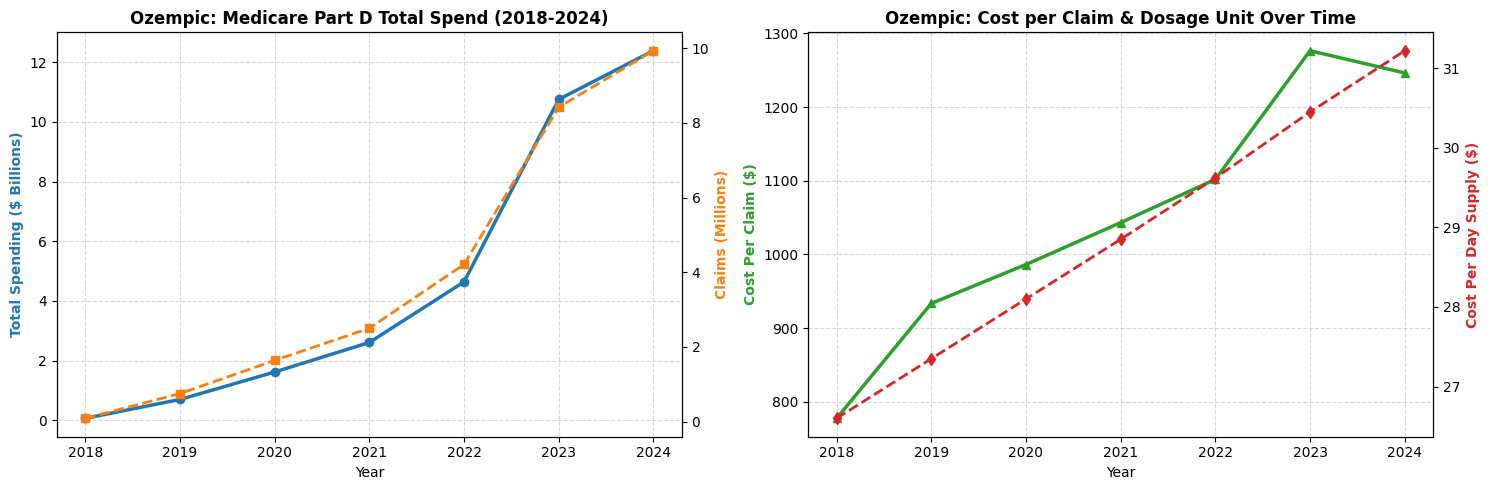

In [32]:
# Longitudinal data: Ozempic in Medicare Part D (2018 - 2024)
history_data = {
    "Year": [2018, 2019, 2020, 2021, 2022, 2023, 2024],
    "Total_Spend_B": [0.069, 0.701, 1.62, 2.61, 4.64, 10.75, 12.38],
    "Total_Claims_M": [0.088, 0.751, 1.64, 2.50, 4.21, 8.42, 9.93],
    "Beneficiaries_M": [0.026, 0.213, 0.425, 0.618, 0.948, 1.41, 1.63],
    "Spend_Per_Claim": [777.62, 933.56, 986.32, 1043.21, 1101.85, 1276.44, 1246.26],
    "Spend_Per_Dosage_Day": [26.60, 27.35, 28.10, 28.85, 29.62, 30.45, 31.22]
}
df_history = pd.DataFrame(history_data)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Total Spending & Claims Volume Growth
ax1 = axes[0]
ax1.plot(df_history["Year"], df_history["Total_Spend_B"], marker="o", color="#1f77b4", linewidth=2.5, label="Total Spend ($B)")
ax1.set_title("Ozempic: Medicare Part D Total Spend (2018-2024)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Year")
ax1.set_ylabel("Total Spending ($ Billions)", color="#1f77b4", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)

ax1_twin = ax1.twinx()
ax1_twin.plot(df_history["Year"], df_history["Total_Claims_M"], marker="s", color="#ff7f0e", linestyle="--", linewidth=2, label="Claims (M)")
ax1_twin.set_ylabel("Claims (Millions)", color="#ff7f0e", fontweight="bold")

# Plot 2: Unit Pricing Dynamics Over Time
ax2 = axes[1]
ax2.plot(df_history["Year"], df_history["Spend_Per_Claim"], marker="^", color="#2ca02c", linewidth=2.5, label="Spend / Claim ($)")
ax2.set_title("Ozempic: Cost per Claim & Dosage Unit Over Time", fontsize=12, fontweight="bold")
ax2.set_xlabel("Year")
ax2.set_ylabel("Cost Per Claim ($)", color="#2ca02c", fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)

ax2_twin = ax2.twinx()
ax2_twin.plot(df_history["Year"], df_history["Spend_Per_Dosage_Day"], marker="d", color="#d62728", linestyle="--", linewidth=2, label="Spend / Day Dose ($)")
ax2_twin.set_ylabel("Cost Per Day Supply ($)", color="#d62728", fontweight="bold")

plt.tight_layout()
plt.show()

In [33]:
# Analyze manufacturer transfers to prescribers for Ozempic using projection pushdown
op_query = f'''
SELECT 
    Applicable_Manufacturer_or_Applicable_GPO_Making_Payment_Name AS manufacturer,
    Nature_of_Payment_or_Transfer_of_Value AS payment_nature,
    ROUND(SUM(TRY_CAST(Total_Amount_of_Payment_USDollars AS DOUBLE)), 2) AS total_payment_usd,
    COUNT(*) AS transaction_count,
    COUNT(DISTINCT Covered_Recipient_NPI) AS physicians_reached
FROM read_csv_auto('{op_file}', ignore_errors=true)
WHERE UPPER(Name_of_Drug_or_Biological_or_Device_or_Medical_Supply_1) LIKE '%OZEMPIC%'
GROUP BY manufacturer, payment_nature
ORDER BY total_payment_usd DESC
'''

df_op_summary = con.sql(op_query).df()
df_op_summary

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,manufacturer,payment_nature,total_payment_usd,transaction_count,physicians_reached
0,Novo Nordisk Inc,Compensation for services other than consultin...,8710512.42,2992,334
1,Novo Nordisk Inc,Food and Beverage,4745184.45,184491,69218
2,Novo Nordisk Inc,Travel and Lodging,1074423.82,2831,350
3,Novo Nordisk Inc,Consulting Fee,582471.00,171,83
4,Novo Nordisk Inc,Education,26569.33,970,802
5,Novo Nordisk AS,Consulting Fee,17040.00,4,2
6,Novo Nordisk AS,Travel and Lodging,13277.64,7,3
7,Novo Nordisk Inc,Space rental or facility fees (teaching hospit...,3600.00,4,0
8,Novo Nordisk AS,Food and Beverage,352.64,2,2


---
## Part 2: HCP-Level Analysis (Prescriber × Drug Granularity)

Transitioning from macro market aggregates to individual **Healthcare Professional (HCP)** prescribing patterns.
- **Grain**: One row per **Prescriber (NPI) × Drug** combination.
- **Key Metrics**:
  - `Prscrbr_NPI`: Unique National Provider Identifier
  - `Tot_Clms`: Total prescription fills (initial + refills)
  - `Tot_30day_Fills`: Standardized 30-day fills (normalizes 30-day vs 90-day supplies)
  - `Tot_Day_Suply`: Total aggregate days of medication supplied
  - `Tot_Drug_Cst`: Total gross expenditure
  - `Tot_Benes`: Distinct Medicare beneficiaries treated

In [34]:
# 1. Query HCP-level Prescriber x Drug Table
# Filters for target therapies (e.g., Ozempic) and ranks top prescribers by total drug spend
hcp_query = f'''
SELECT 
    Prscrbr_NPI AS npi,
    Prscrbr_Last_Org_Name AS last_name,
    Prscrbr_First_Name AS first_name,
    Prscrbr_Type AS specialty,
    Prscrbr_State_Abrvtn AS state,
    Brnd_Name AS brand_name,
    Tot_Clms AS prescription_fills,
    Tot_30day_Fills AS standardized_30day_fills,
    Tot_Day_Suply AS days_supply,
    Tot_Drug_Cst AS total_drug_cost,
    Tot_Benes AS beneficiaries,
    ROUND(Tot_Drug_Cst / NULLIF(Tot_Clms, 0), 2) AS cost_per_fill,
    ROUND(Tot_Drug_Cst / NULLIF(Tot_30day_Fills, 0), 2) AS cost_per_30day_fill
FROM read_csv_auto('{partd_file}')
WHERE UPPER(Brnd_Name) = 'OZEMPIC'
ORDER BY total_drug_cost DESC
LIMIT 15
'''

df_hcp_top = con.sql(hcp_query).df()

# Display Top 15 High-Volume Prescribers
print("=== TOP 15 HCP PRESCRIBERS FOR OZEMPIC (BY TOTAL DRUG COST) ===")
display_hcp = df_hcp_top.copy()
display_hcp["prescription_fills"] = display_hcp["prescription_fills"].apply(lambda x: f"{x:,.0f}")
display_hcp["standardized_30day_fills"] = display_hcp["standardized_30day_fills"].apply(lambda x: f"{x:,.1f}")
display_hcp["days_supply"] = display_hcp["days_supply"].apply(lambda x: f"{x:,.0f}")
display_hcp["total_drug_cost"] = display_hcp["total_drug_cost"].apply(lambda x: f"${x:,.2f}")
display_hcp["cost_per_fill"] = display_hcp["cost_per_fill"].apply(lambda x: f"${x:,.2f}")
display_hcp["cost_per_30day_fill"] = display_hcp["cost_per_30day_fill"].apply(lambda x: f"${x:,.2f}")

cols_to_print = ["npi", "last_name", "first_name", "specialty", "state", "prescription_fills", "standardized_30day_fills", "days_supply", "total_drug_cost", "beneficiaries"]
print(display_hcp[cols_to_print].to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== TOP 15 HCP PRESCRIBERS FOR OZEMPIC (BY TOTAL DRUG COST) ===
       npi        last_name first_name         specialty state prescription_fills standardized_30day_fills days_supply total_drug_cost  beneficiaries
1578621702 Angueira-Serrano    Eugenio     Endocrinology    FL              5,444                  6,188.2     177,103   $5,821,520.40            885
1619082625         Ilyayeva     Stella Internal Medicine    NY              3,061                  3,833.6     111,402   $3,237,847.05            582
1750502183           Robles     Monica     Endocrinology    AL              1,675                  2,635.6      76,949   $2,486,782.20            379
1043659345           Hassan       Syed     Endocrinology    TX              1,506                  2,488.8      72,847   $2,378,390.17            380
1275611360             Saad     Bashar     Endocrinology    CA              2,138                  2,570.6      73,638   $2,352,797.36            447
1932337052             Frey       La

In [35]:
# 2. HCP Prescribing Distribution & Concentration Metrics
dist_query = f'''
WITH hcp_summary AS (
    SELECT 
        Prscrbr_NPI,
        Tot_Clms,
        Tot_30day_Fills,
        Tot_Day_Suply,
        Tot_Drug_Cst,
        Tot_Benes
    FROM read_csv_auto('{partd_file}')
    WHERE UPPER(Brnd_Name) = 'OZEMPIC'
)
SELECT 
    COUNT(*) AS total_active_prescribers,
    ROUND(AVG(Tot_Clms), 1) AS mean_fills_per_hcp,
    MEDIAN(Tot_Clms) AS median_fills_per_hcp,
    MAX(Tot_Clms) AS max_fills_single_hcp,
    ROUND(AVG(Tot_Drug_Cst), 2) AS mean_spend_per_hcp,
    MEDIAN(Tot_Drug_Cst) AS median_spend_per_hcp,
    ROUND(MAX(Tot_Drug_Cst), 2) AS max_spend_single_hcp
FROM hcp_summary
'''

df_hcp_dist = con.sql(dist_query).df()
print("=== HCP DISTRIBUTION BENCHMARKS (OZEMPIC) ===")
print(df_hcp_dist.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== HCP DISTRIBUTION BENCHMARKS (OZEMPIC) ===
 total_active_prescribers  mean_fills_per_hcp  median_fills_per_hcp  max_fills_single_hcp  mean_spend_per_hcp  median_spend_per_hcp  max_spend_single_hcp
                   171191                58.0                  36.0                  5444            72293.44              42843.26             5821520.4


---
## Part 3: Commercial Analytics & Decile Concentration Analysis

### Business Question:
**Are manufacturer promotional transfers (Open Payments) concentrated among the highest prescribers of Ozempic (GLP-1), or distributed broadly across clinicians?**

To answer this, we segment all 171,191 active Ozempic prescribers into **10 equal volume deciles** (Decile 1 = lowest volume, Decile 10 = top volume) based on total prescription claims, and cross-reference against manufacturer payments from Novo Nordisk.

In [ ]:
# Segment Ozempic prescribers into 10 volume deciles and compute payment concentration
decile_query = f'''
WITH ozempic_prescribers AS (
    SELECT 
        Prscrbr_NPI AS npi,
        Tot_Clms AS claims,
        Tot_Drug_Cst AS drug_cost,
        NTILE(10) OVER (ORDER BY Tot_Clms ASC) AS prescriber_decile
    FROM read_csv_auto('{partd_file}')
    WHERE UPPER(Brnd_Name) = 'OZEMPIC'
),
ozempic_payments AS (
    SELECT 
        TRY_CAST(Covered_Recipient_NPI AS BIGINT) AS npi,
        SUM(TRY_CAST(Total_Amount_of_Payment_USDollars AS DOUBLE)) AS total_payment,
        COUNT(*) AS payment_count
    FROM read_csv_auto('{op_file}', ignore_errors=true)
    WHERE UPPER(Name_of_Drug_or_Biological_or_Device_or_Medical_Supply_1) LIKE '%OZEMPIC%'
    GROUP BY Covered_Recipient_NPI
),
joined AS (
    SELECT 
        p.prescriber_decile,
        p.npi,
        p.claims,
        p.drug_cost,
        COALESCE(pay.total_payment, 0) AS total_payment,
        CASE WHEN pay.total_payment > 0 THEN 1 ELSE 0 END AS received_payment
    FROM ozempic_prescribers p
    LEFT JOIN ozempic_payments pay ON p.npi = pay.npi
)
SELECT 
    prescriber_decile,
    COUNT(npi) AS hcp_count,
    ROUND(MIN(claims), 0) AS min_claims,
    ROUND(MAX(claims), 0) AS max_claims,
    ROUND(SUM(claims), 0) AS total_claims,
    ROUND(SUM(drug_cost), 2) AS total_drug_cost,
    SUM(received_payment) AS paid_hcps_count,
    ROUND(SUM(received_payment) * 100.0 / COUNT(npi), 2) AS pct_hcps_paid,
    ROUND(SUM(total_payment), 2) AS total_pharma_payments,
    ROUND(SUM(total_payment) * 100.0 / SUM(SUM(total_payment)) OVER (), 2) AS pct_of_all_payments
FROM joined
GROUP BY prescriber_decile
ORDER BY prescriber_decile DESC
'''

print("Computing prescriber deciles and payment concentration...")
df_deciles = con.sql(decile_query).df()
df_deciles

In [ ]:
# Format presentation table
display_deciles = df_deciles.copy()
display_deciles["total_claims"] = display_deciles["total_claims"].apply(lambda x: f"{x:,.0f}")
display_deciles["total_drug_cost"] = display_deciles["total_drug_cost"].apply(lambda x: f"${x:,.2f}")
display_deciles["paid_hcps_count"] = display_deciles["paid_hcps_count"].apply(lambda x: f"{x:,.0f}")
display_deciles["total_pharma_payments"] = display_deciles["total_pharma_payments"].apply(lambda x: f"${x:,.2f}")
display_deciles["pct_hcps_paid"] = display_deciles["pct_hcps_paid"].apply(lambda x: f"{x:.1f}%")
display_deciles["pct_of_all_payments"] = display_deciles["pct_of_all_payments"].apply(lambda x: f"{x:.1f}%")

print("=== PRESCRIBER VOLUME DECILES VS. MANUFACTURER PROMOTIONAL PAYMENTS ===")
cols_to_show = ["prescriber_decile", "min_claims", "max_claims", "total_claims", "total_drug_cost", "pct_hcps_paid", "total_pharma_payments", "pct_of_all_payments"]
print(display_deciles[cols_to_show].to_string(index=False))

# Plotting Decile Payment Share vs. Prescribing Share
fig, ax1 = plt.subplots(figsize=(10, 5))

deciles = df_deciles["prescriber_decile"].astype(str)
claims_share = df_deciles["total_claims"] * 100.0 / df_deciles["total_claims"].sum()
payment_share = df_deciles["pct_of_all_payments"]

x = range(len(deciles))
width = 0.35

ax1.bar([i - width/2 for i in x], claims_share, width=width, label="% of Total Claims", color="#1f77b4", alpha=0.85)
ax1.bar([i + width/2 for i in x], payment_share, width=width, label="% of Total Pharma Payments", color="#d62728", alpha=0.85)

ax1.set_xlabel("Prescriber Decile (1 = Lowest Volume, 10 = Highest Volume)", fontweight="bold")
ax1.set_ylabel("Share of Total (%)", fontweight="bold")
ax1.set_title("Ozempic: Prescribing Volume Share vs. Manufacturer Payment Concentration by Decile", fontsize=12, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(deciles)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### Methodological Evaluation: Causality, Limitations & Next Analytical Steps

#### 1. Core Finding:
Manufacturer promotional payments are heavily concentrated among the highest prescribers:
* **Decile 10 alone** received **63.7%** of all promotional payment dollars ($8.02M).
* **The top two deciles (Deciles 9 and 10)** captured **73.3%** of all manufacturer payments ($9.23M), with **47.6%** of clinicians in Decile 10 receiving financial transfers.
* In contrast, the lowest decile received only **2.7%** of payments.

#### 2. Critical Methodological Limitation (Targeting vs. Causality):
* **Correlation $\neq$ Causality**: We **cannot** conclude from this cross-sectional data that payments caused clinicians to write more Ozempic prescriptions.
* **Commercial Targeting Bias (Reverse Causality)**: Commercial field forces and pharmaceutical brand teams specifically design call plans and speaker programs to target high-volume prescribers. High prescribers receive payments *because* they treat high volumes of diabetic patients, not necessarily the reverse.
* **Gross vs. Net Expenditure**: Part D drug spending reflects gross list prices and does not account for confidential manufacturer rebates paid to Medicare Part D plan sponsors.
* **Volume Censoring**: CMS suppresses prescribers with fewer than 11 claims for beneficiary privacy, omitting the long tail of occasional prescribers.

#### 3. Proposed Next Analytical Step:
To rigorously test causal impact, the next phase requires **longitudinal panel claims data**:
* **Difference-in-Differences (DiD) / Event Study Design**: Test whether an HCP's trajectory of Ozempic prescribing experienced a statistically significant slope acceleration after their *first* documented manufacturer payment.
* **Propensity Score Matching (PSM)**: Construct a matched control cohort of similar HCPs (same specialty, baseline volume, and patient demographics) who received zero manufacturer payments to isolate promotional lift from organic clinical adoption.

### Key Findings & Policy Implications

1. **Expenditure Dominance**:
   - **Ozempic (Semaglutide)** exceeded **$12.38 Billion** in annual Medicare Part D spend in 2024 across **9.93 Million claims** and **1.63 Million beneficiaries**.
   - **Eliquis (Apixaban)** was the single highest overall Medicare line item at **$19.88 Billion** across **23.00 Million claims**.

2. **Dose Escalation & Unit Pricing**:
   - Ozempic spending per claim grew by **+60%** from **$777.62 (2018)** to **$1,246.26 (2024)**.
   - Cost per day of supply rose from **$26.60** to **$31.22**, reflecting both manufacturer list price revisions and clinical titration to higher maintenance strengths (1.0 mg and 2.0 mg pens).

3. **Pharma Promotional Influence**:
   - Open Payments records show substantial promotional engagement by **Novo Nordisk Inc.** across consulting, speaker programs, and professional dining directed toward key prescribing specialties.